# 023 Fine-tuning of the direct three-class classifier on synthetic slides

**Overview.** This notebook repeats the tuning of `02_2_vector_to_classifier_finetunning.ipynb` (same classes, same model, same search, selection and evaluation) with one change: the model is trained on **synthetic slides** instead of the real ones. The classes are Non-cancer (N, PB, UDH, FEA), non-invasive atypia/neoplasia (ADH and DCIS) and invasive carcinoma (IC).

The synthetic slides are made and saved by `01_2_wsi_to_mod_vectors.ipynb`; this notebook only loads them and runs the results. A synthetic slide is a bag of 4096 or 8192 tile embeddings drawn at random, with replacement, from real slides of one class (at least `K_SLIDES` different real slides, no real slide above `TOP_PERCENTAGE` of the tiles, random tile order). For every cross-validation fold, `N_TOTAL` synthetic slides for training and early stopping, balanced over the classes, are stored in `FEATURES_MOD_DIR/UNI2-h/fold_<k>/` and listed in `labels/BRACS_mod.csv`; they were made only from the real fit and early-stopping slides of that fold, so the held-out patients of the fold contribute no tile (this is checked on loading). The held-out slides of each fold, and the official Testing slides, stay real, with their labels from `labels/BRACS.xlsx` and their vectors from `FEATURES_DIR`: the model is trained on synthetic slides and scored on real ones.

A direct CLAM-MB is tuned by Bayesian optimisation of its learning rate, weight decay, dropout, weight of the coarse auxiliary loss and instance-loss sample size (`k_sample`); the tile cap of notebook 02_2 is not searched because the size of a synthetic slide is fixed. Every trial is a patient-grouped cross-validation over Training + Validation (`utils/mil_cv.py`); its score is the pooled out-of-fold macro-averaged F1 on the real held-out slides. The chosen setting is confirmed with new seeds, its fold models are averaged into an ensemble, and the ensemble is evaluated once on the official Testing set and compared with the three-class model of `02_1_vector_to_classifier_experimentation.ipynb` (section 10) and with the ensemble of notebook 02_2. No choice uses the Testing set.

```mermaid
flowchart TD
    subgraph IN["Inputs"]
        FEAT[("FEATURES_DIR/UNI2-h/<br/>one .pt file per real slide (from 01)")]
        LAB[("labels/BRACS.xlsx<br/>class, patient, official set")]
        MOD[("FEATURES_MOD_DIR/UNI2-h/fold_k/<br/>synthetic .pt files (from 01_2)")]
        LABM[("labels/BRACS_mod.csv<br/>synthetic slides, fold, part, sources")]
        OLD[("classifier/final/<br/>models of 02_1 and 02_2")]
    end

    subgraph S3["3. Data"]
        D1["3.1 build_slide_table + load_bags"]
        D2["3.2 relabel_table<br/>Non-cancer / atypia-neoplasia / IC"]
        D3["3.3 make_cv_folds<br/>patient-grouped, stratified (real slides)"]
        D4["3.4 load_mod_folds<br/>synthetic slides per fold, sources checked<br/>against the fit and early-stopping slides"]
    end

    subgraph S4["4. Bayesian optimisation"]
        B1["objective_factory + run_study<br/>TPE sampler, one trial = one 5-fold CV<br/>(train and stop on synthetic, score on real held-out)"]
        B2["trials_table + plot_tuning"]
    end

    subgraph S5["5-6. Selection and confirmation"]
        C1["select_setting<br/>recall floor, best macro-F1,<br/>one-standard-error rule"]
        C2["cross_validate, 2 repeats,<br/>new seeds, top settings"]
    end

    subgraph S7["7. Ensemble"]
        N1["oof_by_repeat + single_vs_ensemble<br/>out-of-fold, no Testing"]
    end

    subgraph S8["8. Testing set (real slides), used once"]
        E1["predict_ensemble<br/>all fold models"]
        E2["class_views + bootstrap_views<br/>plot_final_results"]
        E3["paired_bootstrap_views<br/>vs the 02_1 and 02_2 models"]
    end

    OUT[("classifier/final/noncancer_noninvasive_invasive_synthetic/<br/>ensemble_date-time.pt")]

    FEAT --> D1
    LAB --> D1
    D1 --> D2
    D2 --> D3
    D3 --> D4
    MOD --> D4
    LABM --> D4
    D4 --> B1
    B1 --> B2
    B2 --> C1
    C1 --> C2
    C2 --> N1
    N1 --> E1
    E1 --> E2
    E1 --> E3
    OLD --> E3
    N1 --> OUT
```

## 1. Setup

The environment is recorded so the run can be reproduced.

In [1]:
# STEP 1: Standard-library imports and general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import optuna
import pandas as pd
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Scikit-learn version:', sklearn.__version__)
print('Optuna version:', optuna.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Scikit-learn version: 1.9.1
Optuna version: 5.1.0
Numpy version: 2.5.4
Pandas version: 3.1.1
Matplotlib version: 3.11.2


The model is trained on the GPU when one is available and on the CPU otherwise (`utils.device.get_device`).

In [2]:
# STEP 1: Select the device (pass e.g. get_device("cpu") to force the CPU)
from utils.device import get_device
DEVICE = get_device()

# STEP 2: Report it
print('Device:', DEVICE, '|', torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else 'no GPU, running on the CPU')

Device: cuda | NVIDIA RTX PRO 4500 Blackwell


The project's own building blocks are imported here. The synthetic slides are in `utils/synthetic_slides.py`; the search, the selection rule and the ensemble file are in `utils/mil_tuning.py`; the data, model, cross-validation and metric code is shared with notebooks 02, 02_1 and 02_2.

In [ ]:
# STEP 1: Standard-library imports
from pathlib import Path

# STEP 2: Import this project's own building blocks
from utils.dataset_overview import build_slide_table
from utils.mil_data import load_bags
from utils.mil_cv import cross_validate, fold_summary, make_cv_folds
from utils.mil_train import device_description, load_classifier, predict, predict_ensemble, set_seed
from utils.classification_metrics import evaluate_predictions
from utils.final_classifier import (bootstrap_views, class_views, format_differences, format_views, paired_bootstrap_views, plot_final_results, relabel_table, summary_across_sets)
from utils.synthetic_slides import load_mod_folds, plot_synthetic_summary
from utils.mil_tuning import (DEFAULT_SPACE, eligible_trials, load_ensemble, objective_factory, oof_by_repeat, plot_tuning, run_study, save_ensemble, score_cv, select_setting, setting_from_row,
                              setting_kwargs, single_vs_ensemble, trials_table)

## 2. Constants

Every setting is defined here. The synthetic slides are read from `FEATURES_MOD_DIR` and `LABELS_MOD_FILE`, written by notebook 01_2; `N_FOLDS`, `EARLY_STOP_FRACTION` and `SEED` must equal the values used there (the sources of every synthetic slide are checked against the folds made here). `K_SLIDES` and `TOP_PERCENTAGE` are only used to check the saved slides and to draw the reference lines of the summary figure. The searched parameters and their ranges are `SPACE`; the first trial is `BASELINE`, the setting of notebook 02_1, so it is scored on the same folds as the others. Everything else is fixed: class weighting, tile dropout, the weight of the slide loss in CLAM-MB, the number of epochs, the early-stopping patience and the number of slides per batch (a synthetic slide has at most 8192 tiles, so four slides per batch keep the tiles per batch at the level of notebook 02_2). With the same number of synthetic slides in every class the class weights are close to one; the weighting is kept so that the loss is the same as in the other notebooks. The coarse auxiliary loss uses two tiers, Non-cancer and lesion (atypia/neoplasia and invasive carcinoma). `MIN_CLASS_RECALL` is a floor on the out-of-fold recall of every class that a setting must reach to be chosen (one value for all classes, a dictionary with one value per class, or None); it is a clinical choice and is not tuned.

The budget is `N_TRIALS` trials, then the best `N_CONFIRM` settings are trained again with `REPEATS` repeats per fold. The ensemble has `N_FOLDS` x `REPEATS` models.

In [ ]:
# Major variables
FEATURES_DIR = Path('/mnt/Scratch/phd_streamembed_features/level_1')    # STEP 1: Folder with one subfolder of .pt files per model
MODEL_NAME = 'UNI2-h'                                                   # STEP 2: Subfolder with the per-slide features
LABELS_FILE = Path('labels/BRACS.xlsx')                                 # STEP 3: Slide labels, patients and official split (real slides)
FEATURES_MOD_DIR = Path('/mnt/Scratch/phd_streamembed_features/level_1_mod')   # STEP 3b: Synthetic vectors written by 01_2 (<dir>/<MODEL_NAME>/fold_<k>/)
LABELS_MOD_FILE = Path('labels/BRACS_mod.csv')                          # STEP 3c: Labels of the synthetic slides written by 01_2
MODEL_DIR = Path('classifier/final')                                    # STEP 4: Folder of the saved classifiers
SAVE_MODELS = True                                                      # STEP 5: Save the ensemble as ensemble_<date-time>.pt
SEED = 0                                                                # STEP 6: Seed of every random choice
N_FOLDS, EARLY_STOP_FRACTION = 5, 0.2                                   # STEP 7: Outer folds; share of the non-held-out slides used to pick the epoch (patient-grouped)
EPOCHS, PATIENCE = 100, 5                                               # STEP 8: Maximum epochs; early-stopping patience (counted after the warm-up)
WEIGHTING, TILE_DROPOUT, BAG_WEIGHT = 'sqrt', 0.5, 0.7                  # STEP 9: Class weighting, share of tiles removed per training bag, weight of the slide loss in CLAM-MB
N_TRIALS = 20                                                           # STEP 10: Trials of the Bayesian optimisation (finished trials; a restart continues the study)
STUDY_DIR = Path('outputs/02_3_tuning')                                 # STEP 11: Folder of the study (SQLite), the trials table
STUDY_NAME = 'three_class_synthetic'                                         # STEP 12: Name of the study inside the database
MIN_CLASS_RECALL = 0.40                                                 # STEP 13: Smallest out-of-fold recall that every class must have (a float, a dict per class, or None)
N_CONFIRM, REPEATS = 2, 2                                               # STEP 14: Settings confirmed with new seeds; repeats per fold (models of the ensemble = folds x repeats)
N_BOOT = 1000                                                           # STEP 15: Bootstrap resamples (patients) for the intervals
THREE_MAPPING = {'N': 'Non-cancer', 'PB': 'Non-cancer', 'UDH': 'Non-cancer', 'FEA': 'Non-cancer',
                 'ADH': 'Non-invasive atypia/neoplasia', 'DCIS': 'Non-invasive atypia/neoplasia', 'IC': 'Invasive carcinoma'}   # STEP 16: BRACS class -> group (order = model outputs)
TIERS_3 = {'non-cancer': ['Non-cancer'], 'lesion': ['Non-invasive atypia/neoplasia', 'Invasive carcinoma']}                      # STEP 17: Tiers of the coarse auxiliary loss
SPACE = {k: v for k, v in DEFAULT_SPACE.items() if k != 'max_tiles'}      # STEP 18: Search ranges: (low, high) numeric, list = categorical (the tile cap is not searched: synthetic slides have a fixed size)
BASELINE = dict(lr=2e-4, weight_decay=1e-1, dropout=0.25, coarse_weight=0.0, k_sample=8)   # STEP 19: First trial: the setting of notebook 02_1
K_SLIDES, TOP_PERCENTAGE = 12, 0.20                                     # STEP 20: Construction settings of 01_2, used only to check the saved slides and in the figure
BATCH_SIZE = 4                                                          # STEP 22: Synthetic slides per batch (4 x 8192 tiles = 16 x 2048 tiles of notebook 02_2)
FIXED = dict(epochs=EPOCHS, patience=PATIENCE, tile_dropout=TILE_DROPOUT, bag_weight=BAG_WEIGHT, weighted_val_loss=True, tiers=TIERS_3, max_tiles=None, batch_size=BATCH_SIZE)   # STEP 23: train_model arguments that are not searched
STUDY_DIR.mkdir(parents=True, exist_ok=True)
set_seed(SEED)

## 3. Data

### 3.1 Slides and tile embeddings

The bags of tile embeddings (UNI2-h CLS tokens) are loaded once; the slide table holds the official split of BRACS.

In [5]:
# STEP 1: Label table with the official split and the bags of tile embeddings (float16)
table = build_slide_table(LABELS_FILE)
data = load_bags(FEATURES_DIR, MODEL_NAME, table)

Loading bags:   0%|          | 0/547 [00:00<?, ?it/s]

Slides with features: 547 of 547  |  tiles 5,748,673  |  tiles per slide: median 9441, min 9, max 35287  |  dim 1536
Per set (with features / labelled): Training 395/395, Validation 65/65, Testing 87/87
Tiling in the files: level 1, tile 448, stride 448


### 3.2 The three classes

Non-cancer groups N, PB, UDH and FEA; ADH and DCIS form one class; IC keeps its own class. The slides per class and part are listed.

In [6]:
# STEP 1: Relabel the table and the bags for the three classes
table3, classes3 = relabel_table(data['table'], THREE_MAPPING)
data3 = {**data, 'table': table3, 'classes': classes3}

# STEP 2: Slides per class and part
pd.crosstab(table3['label'], table3['set']).reindex(classes3)[['Training', 'Validation', 'Testing']]

set,Training,Validation,Testing
label,,,
Non-cancer,227,36,43
Non-invasive atypia/neoplasia,68,17,24
Invasive carcinoma,100,12,20


### 3.3 Cross-validation folds

The official Training and Validation slides are pooled and divided into patient-grouped, class-stratified folds; the Testing slides are in no fold. For every fold a part of the remaining slides is used to select the epoch and the rest to fit the model. The same folds are used by every trial, so the trials are compared on the same held-out slides.

In [7]:
# STEP 1: The folds (the Testing slides are left out of every fold)
real_folds = make_cv_folds(table3, N_FOLDS, SEED, EARLY_STOP_FRACTION)

# STEP 2: Slides and patients per part, and the held-out slides per class
fold_summary(real_folds, classes3)

,fold,fit,early stopping,held out,held-out patients,Non-cancer,Non-invasive atypia/neoplasia,Invasive carcinoma
0,0,293,74,93,34,53,17,23
1,1,295,72,93,33,53,17,23
2,2,295,73,92,33,53,17,22
3,3,294,75,91,29,52,17,22
4,4,297,72,91,29,52,17,22


### 3.4 Synthetic slides

The synthetic slides of every fold are read from `FEATURES_MOD_DIR` (one file per slide, in the sub-folder of the fold) and `LABELS_MOD_FILE`; their construction is described in notebook 01_2. `load_mod_folds` adds to each real fold its training and early-stopping tables (`train_table`, the synthetic slides only) and their bags, which are read from disk when a batch is built. It stops with an error if a file is missing or if a source of a synthetic slide is not a fit (or early-stopping) slide of the same fold, which happens when the folds made here differ from those of 01_2.

The held-out slides of every fold are not sources, so the synthetic slides of a fold contain no tile of the patients that are scored with it. The real table of the fold and its held-out list are unchanged, so the held-out slides are scored as real slides and the out-of-fold estimate is comparable with that of notebook 02_2.

In [ ]:
# STEP 1: Synthetic slides of every fold, read from disk and checked against the folds
folds = load_mod_folds(real_folds, FEATURES_MOD_DIR, LABELS_MOD_FILE, MODEL_NAME)

# STEP 2: Table of the synthetic slides, with a check of the construction rules
synthetic = pd.read_csv(LABELS_MOD_FILE).rename(columns={'WSI Filename': 'slide', 'WSI label': 'label'})
assert synthetic['n_sources'].min() >= K_SLIDES and synthetic['max_share'].max() <= TOP_PERCENTAGE + 1e-9, 'the saved slides break the rules of the construction'
assert set(synthetic['label']) <= set(classes3), 'unknown class in the label file'

# STEP 3: Synthetic slides per fold, part and class
display(synthetic.groupby(['fold', 'part', 'label']).size().unstack().rename_axis(columns=None))
synthetic[['size', 'n_sources', 'max_share']].describe().round(3)

### 3.5 Properties of the synthetic slides

The figure shows how the rules of the construction are used by the saved slides.

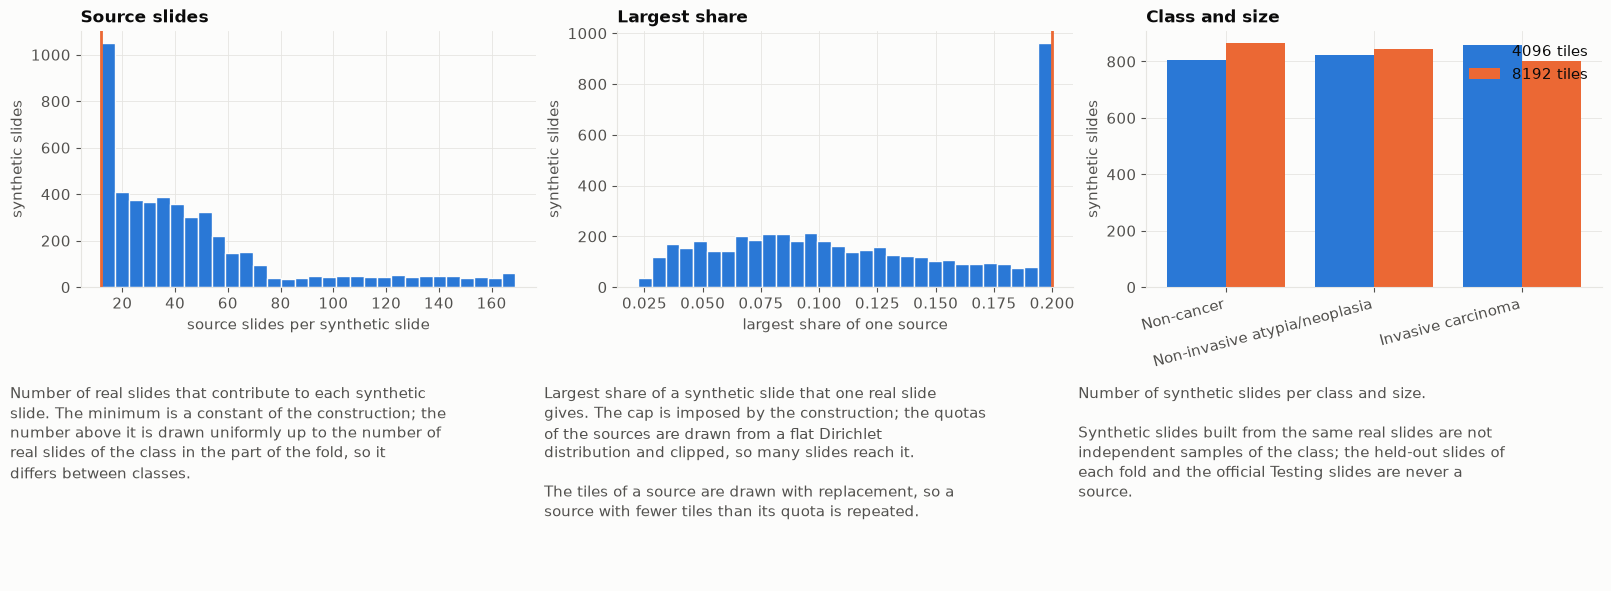

In [9]:
# STEP 1: Figure
fig_synthetic = plot_synthetic_summary(synthetic, TOP_PERCENTAGE, K_SLIDES)

## 4. Bayesian optimisation

One trial trains `N_FOLDS` models, one per fold, with a sampled setting and returns the pooled out-of-fold macro-averaged F1. The optimiser is the tree-structured Parzen estimator of optuna (Bergstra et al., 2011), which after ten random trials proposes settings from the results so far; the study is stored in SQLite, so a restart continues it. Every model is trained and stopped on the synthetic slides of its fold and scored on the real held-out slides of the fold. A trial is slower than in notebook 02_2 because a synthetic slide has 4096 or 8192 tiles and the slide is assembled from the real bags in every epoch.

In [10]:
# STEP 1: The objective (one trial = one cross-validation) and the study
objective = objective_factory(data3, folds, DEVICE, FIXED, WEIGHTING, SEED, SPACE)
study = run_study(STUDY_NAME, f'sqlite:///{STUDY_DIR / "study.db"}', objective, N_TRIALS, SEED, BASELINE)

[I 2026-11-16 19:24:11,012] A new study created in RDB with name: three_class_synthetic


  0%|          | 0/20 [00:00<?, ?it/s]

[W 2026-11-16 19:27:40,154] Trial 0 failed with parameters: {'lr': 0.0002, 'weight_decay': 0.1, 'dropout': 0.25, 'coarse_weight': 0.0, 'k_sample': 8} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/home/guisazevedo/Projects/01_accamargo/phd_streamembed/.venv/lib/python3.14/site-packages/optuna/study/_optimize.py", line 210, in _run_trial
    value_or_values = func(trial)
  File "/home/guisazevedo/Projects/01_accamargo/phd_streamembed/utils/mil_tuning.py", line 116, in objective
    cv = cross_validate("clam_mb", data, folds, device, weighting, 1, seed, **setting_kwargs(setting, fixed))
  File "/home/guisazevedo/Projects/01_accamargo/phd_streamembed/utils/mil_cv.py", line 143, in cross_validate
    run = train_model(model_name, fold_dataset, training_class_weights(fold_dataset, weighting), device, seed + 1000 * repeat + k, verbose=False, **train_kwargs)
  File "/home/guisazevedo/Projects/01_accamargo/phd_streamembed/utils/mil_train.py", l

KeyboardInterrupt: 

### 4.1 Trials

Every finished trial with its parameters, the pooled out-of-fold macro-F1, the out-of-fold recall and F1 of each class, the standard deviation over folds and the minutes it took. Trial 0 is the setting of notebook 02_1.

In [ ]:
# STEP 1: The trials table, best first (ties: lower log-loss)
trials = trials_table(study)
trials.to_csv(STUDY_DIR / 'trials_three_class_synthetic.csv', index=False)
trials.round(3)

### 4.2 Optimisation history and importance

In [ ]:
# STEP 1: Figure
fig_tuning = plot_tuning(study)

### 4.3 Best recall per class

The highest out-of-fold recall that any trial reached for each class. A recall floor above these values would remove every trial.

In [ ]:
# STEP 1: Best out-of-fold recall of each class over the trials
trials[[f'recall_{c}' for c in classes3]].max().round(3).to_frame('best recall').T

## 5. Selection

The final setting is chosen without the Testing set, in three steps: settings in which some class has an out-of-fold recall below `MIN_CLASS_RECALL` are removed; the best pooled macro-F1 is found among the rest; and among the settings within one standard error of it (the standard error of the fold macro-F1 values), the one with the higher dropout, then the higher weight decay is taken (one-standard-error rule, Hastie et al., 2009). Macro-F1 gives every class the same weight, which suits the smaller classes; sensitivity alone is not used, since it is maximised by assigning every slide to the class.

In [ ]:
# STEP 1: Chosen setting and the candidates within one standard error of the best
chosen, candidates = select_setting(trials, MIN_CLASS_RECALL, classes3)
display(candidates.round(3))
print('Chosen: trial', int(chosen['trial']), setting_from_row(chosen))

## 6. Confirmation with new seeds

The chosen setting and the next best settings are trained again with `REPEATS` repeats per fold and seeds that the search did not use, because the best value of many trials is optimistic. The same selection rule is then applied to these scores, and the final setting is the one it chooses.

In [ ]:
# STEP 1: The settings to confirm: the chosen one, then the best remaining ones
order = [int(chosen['trial'])] + [int(t) for t in eligible_trials(trials, MIN_CLASS_RECALL, classes3)['trial'] if int(t) != int(chosen['trial'])]
confirm_trials = order[:N_CONFIRM]

# STEP 2: Cross-validation of each with REPEATS repeats and new seeds
cvs, rows = {}, []
for number in confirm_trials:
    setting = setting_from_row(trials[trials['trial'] == number].iloc[0])
    cvs[number] = cross_validate('clam_mb', data3, folds, DEVICE, WEIGHTING, REPEATS, SEED + 5000, **setting_kwargs(setting, FIXED))
    rows.append({'trial': number, **setting, **score_cv(cvs[number], classes3)})
confirmation = pd.DataFrame(rows).sort_values(['macro_f1', 'log_loss'], ascending=[False, True]).reset_index(drop=True)
confirmation.round(3)

The same selection rule is applied to the confirmation scores, which come from `REPEATS` models per fold, and gives the final setting and its fold models.

In [ ]:
# STEP 1: The final setting by the same rule
final, final_candidates = select_setting(confirmation, MIN_CLASS_RECALL, classes3)
final_trial, final_setting = int(final['trial']), setting_from_row(final)
final_cv = cvs[final_trial]
print('Final: trial', final_trial, final_setting)

## 7. Ensemble

The ensemble consists of the models of the final setting only: one per fold and repeat, `N_FOLDS` x `REPEATS` models, each trained on a different patient-grouped part of Training + Validation and stopped at its own epoch. A held-out slide is predicted by the models of its own fold and their probabilities are averaged, which gives the out-of-fold estimate below without the Testing set; on the Testing set all models predict every slide. Models of different settings are not mixed, because the same folds ranked the settings. The table compares each single repeat with the average of the repeats; the average over the confirmed settings is shown for comparison.

In [ ]:
# STEP 1: Single repeats against the ensemble, on the out-of-fold slides
per_repeat = oof_by_repeat(final_cv, data3, folds, DEVICE)
display(single_vs_ensemble(final_cv, per_repeat, classes3).round(3))

# STEP 2: For comparison, the average over the confirmed settings (the same folds ranked them, so this is optimistic)
from sklearn.metrics import f1_score
mixed = np.mean([cvs[t]['proba'] for t in confirm_trials], axis=0)
print('Macro F1 of the ensemble of the final setting:', round(score_cv(final_cv, classes3)['macro_f1'], 3),
      '| of the average over the confirmed settings:', round(f1_score(final_cv['y'], mixed.argmax(1), average='macro'), 3))

## 8. Evaluation on the Testing set

The Testing labels are read here for the first time. Every model of the ensemble predicts every Testing slide and the probabilities are averaged; the class with the highest probability is the prediction. For each class the measures are computed one class against the rest (for the macro row, the multi-class accuracy and the unweighted mean of the others), with 95% intervals from a bootstrap that resamples patients.

### 8.1 Confusion matrix, ROC curves and measures

In [ ]:
# STEP 1: Testing slides, in table order, and the ensemble probabilities
test = table3[table3['set'] == 'Testing'].reset_index(drop=True)
y_test = np.array([classes3.index(l) for l in test['label']])
patients_test = test['patient'].to_numpy()
proba_test = predict_ensemble(final_cv['runs'], data3, test['slide'].tolist(), DEVICE)['proba']

# STEP 2: Measures with patient-bootstrap intervals, figure and table
NAME = 'Synthetic-trained 3-class ensemble'
evaluation = evaluate_predictions(y_test, proba_test, classes3)
views = {NAME: class_views(y_test, proba_test, classes3)}
intervals = {NAME: bootstrap_views(y_test, proba_test, patients_test, classes3, N_BOOT, SEED)}
fig_test = plot_final_results(NAME, evaluation['confusion'], y_test, proba_test, classes3)
display(format_views(views[NAME], intervals[NAME]))

### 8.2 Comparison with the direct three-class model of notebook 02_1

The model saved by section 10 of notebook 02_1 (`classifier/final/noncancer_adhdcis_ic/`, classes Non-cancer, ADH&DCIS and IC, the same slides in the same groups) predicts the same Testing slides. The difference (synthetic-trained ensemble minus that model) comes with a 95% interval from a paired patient bootstrap, in which both models are scored on the same resamples. An interval that contains zero is not distinguishable from no change at this sample size (87 slides, 31 patients).

In [ ]:
# STEP 1: The previous direct three-class model (the latest file of its folder), on the same slides
previous_files = sorted((MODEL_DIR / 'noncancer_adhdcis_ic').glob('classifier_model_*.pt'))
if not previous_files:
    print('No classifier in', MODEL_DIR / 'noncancer_adhdcis_ic', ': run section 10 of notebook 02_1 first. Comparison skipped.')
else:
    previous = load_classifier(previous_files[-1], DEVICE)
    assert len(previous['classes']) == len(classes3), 'The two models must have the same number of classes'
    assert previous['classes'][0] == 'Non-cancer' and previous['classes'][-1] == 'IC', 'The class order of the two models must be the same (the group names differ)'
    proba_previous = predict(previous['model'], data3, test['slide'].tolist(), DEVICE, previous['scaler'])['proba']

    # STEP 2: Measures of both, and the paired bootstrap of the difference
    views['Direct 3-class (02_1)'] = class_views(y_test, proba_previous, classes3)
    display(summary_across_sets(views).round(3))
    differences = paired_bootstrap_views(y_test, proba_test, proba_test.argmax(1), proba_previous, proba_previous.argmax(1), patients_test, classes3, N_BOOT, SEED)
    display(format_differences(differences))

### 8.3 Comparison with the tuned ensemble of notebook 02_2

The ensemble saved by notebook 02_2 (`classifier/final/noncancer_noninvasive_invasive_tuned/`) uses the same classes, folds and search, but is trained on real slides. Both ensembles predict the same Testing slides, and the difference (synthetic-trained minus real-trained) comes with a 95% interval from the paired patient bootstrap. The comparison isolates the effect of the synthetic slides together with the setting that the search chose for them; the two searches are separate, so it is not a test of synthetic slides at a fixed setting.

In [ ]:
# STEP 1: The ensemble of notebook 02_2 (the latest file of its folder), on the same slides
tuned_files = sorted((MODEL_DIR / 'noncancer_noninvasive_invasive_tuned').glob('ensemble_*.pt'))
if not tuned_files:
    print('No ensemble in', MODEL_DIR / 'noncancer_noninvasive_invasive_tuned', ': run notebook 02_2 first. Comparison skipped.')
else:
    tuned = load_ensemble(tuned_files[-1], DEVICE)
    assert tuned['classes'] == classes3, 'The two ensembles must have the same classes in the same order'
    proba_tuned = predict_ensemble(tuned['runs'], data3, test['slide'].tolist(), DEVICE)['proba']

    # STEP 2: Measures of both, and the paired bootstrap of the difference
    views['Tuned on real slides (02_2)'] = class_views(y_test, proba_tuned, classes3)
    display(summary_across_sets(views).round(3))
    differences = paired_bootstrap_views(y_test, proba_test, proba_test.argmax(1), proba_tuned, proba_tuned.argmax(1), patients_test, classes3, N_BOOT, SEED)
    display(format_differences(differences))

## 9. Save

The ensemble is written to one file with the weights, scaler and settings of every model (`utils.mil_tuning.save_ensemble`; `load_ensemble` returns the models for `predict_ensemble`). The configuration records the searched ranges, the final setting and the study.

In [ ]:
# STEP 1: What is needed to reproduce and to reuse the ensemble
config = dict(
    synthetic=dict(k_slides=K_SLIDES, top_percentage=TOP_PERCENTAGE, vectors=str(FEATURES_MOD_DIR / MODEL_NAME), labels=str(LABELS_MOD_FILE), n_synthetic=len(synthetic)),
    seed=SEED, n_folds=N_FOLDS, repeats=REPEATS, early_stop_fraction=EARLY_STOP_FRACTION, weighting=WEIGHTING, fixed={k: v for k, v in FIXED.items() if k != 'tiers'}, tiers=TIERS_3,
    final_trial=final_trial, final_setting=final_setting, space={k: list(v) if isinstance(v, (tuple, list)) else v for k, v in SPACE.items()}, n_trials=N_TRIALS, min_class_recall=MIN_CLASS_RECALL,
    mapping=THREE_MAPPING, classes=classes3, features_dir=str(FEATURES_DIR), model_name=MODEL_NAME, tile_params=data['tile_params'], device=device_description(DEVICE),
    versions=dict(torch=torch.__version__, sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__, optuna=optuna.__version__), dropped_slides=data['missing'],
)

# STEP 2: Save the models of the ensemble
if SAVE_MODELS:
    path = save_ensemble(final_cv['runs'], MODEL_DIR / 'noncancer_noninvasive_invasive_synthetic', config)
    print('Ensemble of', len(final_cv['runs']), 'models saved to', path.resolve())
else:
    print('SAVE_MODELS is False: nothing was written.')